| Subject Code | Assignment No. |
|:------------:|:--------------:|
| CS69101      | Lab 6          |

Given a set of integer elements stored in an input file, `input.txt`, construct a **Segment Tree** to efficiently perform **Range Minimum Query (RMQ)** and **Range Maximum Query** operations.

The Segment Tree should store both the minimum and maximum values corresponding to each segment of the input array. Implement range query and point update operations while maintaining the correctness of the Segment Tree.

In [1]:
import os
import sys
from io import TextIOWrapper
from typing import Self, Any, Callable, TypeVar, Generic, Optional
import random
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.pylab import figure

sys.setrecursionlimit(100000) # Fix to avoid RecursionError

os.makedirs("./lab6_v2_data", exist_ok=True)

prep_arr = [random.randint(1, (i+1)*10) for i in range(10000)] # Random Array of 10000 Elements
# prep_arr.sort() # Sorted Array for Worst Case Scenario
print(prep_arr[:25])
print(len(prep_arr))

# Write the array to a file
f = open("./lab6_v2_data/input0.txt", "w")
for i in prep_arr:
    f.write(f"{i}, ")
f.write("\n")
f.close()

del prep_arr
del f

iterations = 0
PRINT_DEBUG = False

[7, 3, 17, 2, 45, 19, 14, 42, 82, 5, 40, 64, 56, 71, 125, 51, 55, 147, 130, 157, 127, 60, 173, 23, 248]
10000


# Q1.

Read integer elements from `input.txt` and construct a Segment Tree using the given array elements.

## File Read

In [3]:
# Read a set of integer elements from an input file (input.txt)
arr0 = []
data0 = open("./lab6_v2_data/input.txt", 'r')

try:
    for line in data0.readlines():
        line_data = line.rstrip().rstrip(',').replace(',',' ').split() #using rstrip to remove the \n
        for data in line_data:
            arr0.append(int(data))
    data0.close()
except Exception as e:
    sys.exit("[ERROR] Invalid data" + str(e))

n = len(arr0)
assert n >= 4, "input.txt must contain at least 4 integer elements"

In [4]:
print(arr0)

[12, 5, 18, 3, 9, 21, 7, 14]


## Segment Tree

In [5]:
# LEGACY CODE LOL

# class Segment_Node:
#     def __init__(self, value: int | None = None):
#         self.__lchild = None
#         self.__rchild = None
#         self.__value = None

#     def find_leaf(self) -> Self:
#         if self.__lchild is None and self.__rchild is None:
#             return self
#         elif self.__lchild is not None:
#             return self.__lchild.find_leaf()
#         else:
#             assert self.__rchild is not None # This is to shut the LSP up.
#             return self.__rchild.find_leaf()
    
#     def insert(self, value: int) -> Self: # Guess why this is wrong.
#         if self.__value is None:
#             self.__value = value
#         if self.__value == value:
#             return self
#         elif value < self.__value: #
#             if self.__lchild is None:
#                 new_node = type(self)(value) # type(self) instead of Segment_Node to shut the linter up.
#                 self.__lchild = (new_node)
#             else:
#                 self.__lchild.insert(value)
#         else:
#             if self.__rchild is None:
#                 new_node = type(self)(value)
#                 self.__rchild = new_node
#             else:
#                 self.__rchild.insert(value)
#         return self

In [6]:
class Segment_Tree:
    def __init__(self):
        self.__size = 0
        self.__min = []  # minimum of every segment (heap-indexed: children of i are 2i+1 and 2i+2)
        self.__max = []  # maximum of every segment

    def __node(self, index: int) -> tuple[int, int]:
        return (self.__min[index], self.__max[index])

    # Q4: combine the (minimum, maximum) results of two child nodes
    def merge(self, left: tuple[int, int], right: tuple[int, int]) -> tuple[int, int]:
        return (min(left[0], right[0]), max(left[1], right[1]))

    # Q2: build the tree over arr; every node stores the minimum and the maximum of its segment
    def build(self, arr: list[int], left_bound: int = 0, right_bound: int | None = None, index: int = 0) -> None:
        global iterations
        if right_bound is None:  # top-level call: allocate the tree for len(arr) elements
            assert len(arr) > 0, "Cannot build a Segment Tree over an empty array"
            self.__size = len(arr)
            self.__min = [0] * 4 * self.__size
            self.__max = [0] * 4 * self.__size
            right_bound = self.__size - 1
        iterations += 1  # one node visited
        if left_bound == right_bound:
            self.__min[index] = self.__max[index] = arr[left_bound]
            return
        mid = (left_bound + right_bound) // 2
        left_child_index = index * 2 + 1
        right_child_index = index * 2 + 2

        self.build(arr, left_bound, mid, left_child_index)
        self.build(arr, mid + 1, right_bound, right_child_index)

        self.__min[index], self.__max[index] = self.merge(self.__node(left_child_index), self.__node(right_child_index))

    # Q3: (minimum, maximum) of arr[query_start..query_end]
    def query(self, query_start: int, query_end: int, left_bound: int = 0, right_bound: int | None = None, index: int = 0) -> Optional[tuple[int, int]]:
        global iterations
        if right_bound is None:  # top-level call
            assert 0 <= query_start <= query_end < self.__size, f"Invalid range [{query_start}, {query_end}]"
            right_bound = self.__size - 1
        iterations += 1  # one node visited
        if right_bound < query_start or query_end < left_bound:
            return None  # segment lies completely outside the query range

        if query_start <= left_bound and right_bound <= query_end:
            return self.__node(index)  # segment lies completely inside the query range

        mid = (left_bound + right_bound) // 2
        left_child_index = index * 2 + 1
        right_child_index = index * 2 + 2

        left_result = self.query(query_start, query_end, left_bound, mid, left_child_index)
        right_result = self.query(query_start, query_end, mid + 1, right_bound, right_child_index)

        if left_result is not None and right_result is not None:
            return self.merge(left_result, right_result)
        elif left_result is not None:
            return left_result
        else:
            return right_result

    # Q5: set arr[target_index] = value and recompute every segment on the path to the root
    def update(self, target_index: int, value: int, left_bound: int = 0, right_bound: int | None = None, index: int = 0) -> None:
        global iterations
        if right_bound is None:  # top-level call
            assert 0 <= target_index < self.__size, f"Invalid index {target_index}"
            right_bound = self.__size - 1
        iterations += 1  # one node visited
        if left_bound == right_bound:
            self.__min[index] = self.__max[index] = value
            return
        mid = (left_bound + right_bound) // 2
        left_child_index = index * 2 + 1
        right_child_index = index * 2 + 2

        if target_index <= mid:
            self.update(target_index, value, left_bound, mid, left_child_index)
        else:
            self.update(target_index, value, mid + 1, right_bound, right_child_index)

        self.__min[index], self.__max[index] = self.merge(self.__node(left_child_index), self.__node(right_child_index))

    # Height in levels (a single node is 1)
    def height(self, left_bound: int = 0, right_bound: int | None = None) -> int:
        if right_bound is None:
            assert self.__size > 0, "The tree has not been built yet"
            right_bound = self.__size - 1
        if left_bound == right_bound:
            return 1
        mid = (left_bound + right_bound) // 2
        return 1 + self.height(left_bound, mid)  # the left half is never smaller than the right half, so it is the deepest

    # Q6: one line per node, indented by depth (pre-order)
    def representation(self, left_bound: int = 0, right_bound: int | None = None, index: int = 0, depth: int = 0) -> list[str]:
        if right_bound is None:
            right_bound = self.__size - 1
        line = f"{'    ' * depth}[{left_bound}, {right_bound}]  minimum = {self.__min[index]}, maximum = {self.__max[index]}"
        if left_bound == right_bound:
            return [line]
        mid = (left_bound + right_bound) // 2
        return ([line]
                + self.representation(left_bound, mid, index * 2 + 1, depth + 1)
                + self.representation(mid + 1, right_bound, index * 2 + 2, depth + 1))

## Linear Range Search
Baseline for Q8: scan every element of `[query_start, query_end]` once, keeping the running minimum and maximum.

In [7]:
def linear_range_search(arr: list[int], query_start: int, query_end: int, index: int | None = None) -> tuple[int, int]:
    global iterations
    if index is None:
        index = query_start
    iterations += 1  # one element scanned
    if index == query_end:
        return (arr[index], arr[index])
    rest_min, rest_max = linear_range_search(arr, query_start, query_end, index + 1)
    return (min(arr[index], rest_min), max(arr[index], rest_max))

In [8]:
stree0 = Segment_Tree()

# Q2.

Implement the `build()` operation to construct the Segment Tree such that each node stores:

- Minimum value of its corresponding range.
- Maximum value of its corresponding range.

## build()

In [9]:
iterations = 0
stree0.build(arr0)

print(f"build() visited {iterations} nodes for {n} elements (2n - 1 = {2 * n - 1}).")
print(f"Tree height: {stree0.height()} levels")

build() visited 15 nodes for 8 elements (2n - 1 = 15).
Tree height: 4 levels


# Q3.

Implement `query(L, R)` to find:

- Minimum element in the range [L, R].
- Maximum element in the range [L, R].

## Query File Read

In [11]:
# queries.txt: the number of range queries, followed by one "L R" pair per line
queries = []
try:
    data1 = open("./lab6_v2_data/queries.txt", 'r')
    num_queries = int(data1.readline())
    for _ in range(num_queries):
        left, right = map(int, data1.readline().split())
        assert 0 <= left <= right < n, f"Query [{left}, {right}] is outside the array"
        queries.append((left, right))
    data1.close()
except Exception as e:
    sys.exit("[ERROR] Invalid queries" + str(e))

print(queries)

[(0, 3), (2, 6), (1, 5), (4, 7)]


## query()

In [12]:
def verify_queries(tree: Segment_Tree, arr: list[int], max_checks: int = 500) -> None:
    # Compare the tree with brute force on every range (or on a random subset of max_checks ranges)
    ranges = [(l, r) for l in range(len(arr)) for r in range(l, len(arr))]
    if len(ranges) > max_checks:
        ranges = random.sample(ranges, max_checks)
    for left, right in ranges:
        assert tree.query(left, right) == (min(arr[left:right + 1]), max(arr[left:right + 1])), f"query({left}, {right}) is wrong"
    print(f"Verified {len(ranges)} range queries against brute force.")

random.seed(911)  # reproducible random checks and updates
verify_queries(stree0, arr0)

Verified 36 range queries against brute force.


# Q4.

Implement a `merge()` operation to combine the results of two child nodes:

- minimum = min(left.minimum, right.minimum)
- maximum = max(left.maximum, right.maximum)

## merge()

In [13]:
# Merging the results of the two halves of the array must give the result for the whole array
half = n // 2
left_result, right_result = stree0.query(0, half - 1), stree0.query(half, n - 1)
merged = stree0.merge(left_result, right_result)
assert merged == stree0.query(0, n - 1)
print(f"merge({left_result}, {right_result}) = {merged}")

merge((3, 18), (7, 21)) = (3, 21)


# Q5.

Implement `update(index, value)` to modify an element at a specified index and update all affected nodes of the Segment Tree.

## update()

In [14]:
# Updates are applied to a separate copy so that stree0 is untouched for Q6
check_arr = arr0.copy()
check_tree = Segment_Tree()
check_tree.build(check_arr)

for _ in range(20):
    index, value = random.randrange(n), random.randint(1, 10 * n)
    check_tree.update(index, value)
    check_arr[index] = value

verify_queries(check_tree, check_arr)

Verified 36 range queries against brute force.


# Q6.

Display the following after construction:

- Original array.
- Segment Tree representation.
- Minimum value of a specified range.
- Maximum value of the same range.

The result after every point update is displayed as well, and everything is stored in `output.txt`.

## Display

In [15]:
output_lines = []

def emit(line: str = "") -> None:
    print(line)
    output_lines.append(line)

def emit_query(tree: Segment_Tree, left: int, right: int) -> None:
    minimum, maximum = tree.query(left, right)
    emit(f"Query [{left}, {right}]")
    emit(f"Minimum = {minimum}")
    emit(f"Maximum = {maximum}")

emit("Original array:")
emit(" ".join(map(str, arr0)))
emit()
emit("Segment Tree:")
for line in stree0.representation():
    emit(line)
emit()

for left, right in queries:
    emit_query(stree0, left, right)
    emit()

# The first update is the one from the assignment's example; the others are random
updates = [(3, 25)] + [(random.randrange(n), random.randint(1, 10 * n)) for _ in range(2)]
current = arr0.copy()
for index, value in updates:
    stree0.update(index, value)
    current[index] = value
    assert stree0.query(0, n - 1) == (min(current), max(current))
    emit("Update:")
    emit(f"Index = {index}")
    emit(f"New Value = {value}")
    emit_query(stree0, 0, n - 1)
    emit()

Original array:
12 5 18 3 9 21 7 14

Segment Tree:
[0, 7]  minimum = 3, maximum = 21
    [0, 3]  minimum = 3, maximum = 18
        [0, 1]  minimum = 5, maximum = 12
            [0, 0]  minimum = 12, maximum = 12
            [1, 1]  minimum = 5, maximum = 5
        [2, 3]  minimum = 3, maximum = 18
            [2, 2]  minimum = 18, maximum = 18
            [3, 3]  minimum = 3, maximum = 3
    [4, 7]  minimum = 7, maximum = 21
        [4, 5]  minimum = 9, maximum = 21
            [4, 4]  minimum = 9, maximum = 9
            [5, 5]  minimum = 21, maximum = 21
        [6, 7]  minimum = 7, maximum = 14
            [6, 6]  minimum = 7, maximum = 7
            [7, 7]  minimum = 14, maximum = 14

Query [0, 3]
Minimum = 3
Maximum = 18

Query [2, 6]
Minimum = 3
Maximum = 21

Query [1, 5]
Minimum = 3
Maximum = 21

Query [4, 7]
Minimum = 7
Maximum = 21

Update:
Index = 3
New Value = 25
Query [0, 7]
Minimum = 5
Maximum = 25

Update:
Index = 2
New Value = 57
Query [0, 7]
Minimum = 5
Maximum = 57

Up

## Output

In [16]:
with open("./lab6_v2_data/output.txt", "w") as out_file:
    out_file.write("\n".join(output_lines).rstrip("\n") + "\n")

# Q7.

For different numbers of elements, such as 100, 500, 1000, 5000 and 10000, measure and plot:

- Construction Time vs. Number of Elements
- Range Query Time vs. Number of Elements
- Point Update Time vs. Number of Elements
- Tree Height vs. Number of Elements

Time is measured as the number of iterations: one iteration is one node visited (one element scanned for the linear search).

**Method.** As in lab 3, one window of 10000 consecutive elements, starting at a random index of `input0.txt`, grows by one element at a time, and everything is recorded for every size *k* from 1 to 10000: the Segment Tree is built on the first *k* elements (tree height and construction iterations), then one random range query and one random point update are performed on it (iterations of each). Every size is therefore measured once.

In [17]:
arr1 = []
with open("./lab6_v2_data/input0.txt", 'r') as data0:
    for line in data0.readlines():
        line_data = line.rstrip().rstrip(',').replace(' ','').split(',')
        for data in line_data:
            arr1.append(int(data))

In [18]:
SIZES = [100, 500, 1000, 5000, 10000]
N = SIZES[-1]

random.seed(911)

def ST_Build_Measured(values: list[int]):
    global iterations
    iterations = 0
    stree = Segment_Tree()
    stree.build(values)
    return stree, iterations


def ST_Query_Measured(stree: Segment_Tree, left: int, right: int):
    global iterations
    iterations = 0
    result = stree.query(left, right)
    return result, iterations


def ST_Update_Measured(stree: Segment_Tree, index: int, value: int):
    global iterations
    iterations = 0
    stree.update(index, value)
    return stree, iterations


def Linear_Search_Measured(values: list[int], left: int, right: int):
    global iterations
    iterations = 0
    result = linear_range_search(values, left, right)
    return result, iterations


def ST_Recorded(values: list[int], query_ranges: list, point_updates: list) -> dict:
    height_store, construction_counts, query_counts, update_counts = [], [], [], []
    for k in range(1, len(values) + 1):
        window = values[:k]  # the first k elements
        stree, build_count = ST_Build_Measured(window)
        height_store.append(stree.height())  # recorded once for every size, as in lab 3
        assert build_count == 2 * k - 1, "construction must visit exactly 2k - 1 nodes"
        construction_counts.append(build_count)

        left, right = query_ranges[k - 1]
        result, query_count = ST_Query_Measured(stree, left, right)
        assert result == (min(window[left:right + 1]), max(window[left:right + 1])), f"query({left}, {right}) is wrong"
        assert query_count <= 4 * height_store[-1], "a query visits at most 4 nodes per level"
        query_counts.append(query_count)

        index, value = point_updates[k - 1]
        update_counts.append(ST_Update_Measured(stree, index, value)[1])
        assert update_counts[-1] <= height_store[-1], "an update visits at most one node per level"
        window[index] = value
        assert stree.query(0, k - 1) == (min(window), max(window)), "Segment Tree is wrong after the update"

    return {"Height": height_store, "Construction": construction_counts, "Query": query_counts, "Update": update_counts}


def size_mean(series: list, n: int) -> float:
    # Mean of the values recorded for the last 10% of the sizes up to n (smooths the per-size noise)
    window = series[n - max(1, n // 10) : n]
    return sum(window) / len(window)


assert N <= len(arr1), "n cannot exceed the length of arr1"
start_idx = random.randint(0, len(arr1) - N)
random_values = arr1[start_idx : start_idx + N]

# The operations of size k: a random range [L, R] of the k elements and a random point update
query_ranges, point_updates = [], []
for k in range(1, N + 1):
    left = random.randrange(k)
    query_ranges.append((left, random.randrange(left, k)))
    point_updates.append((random.randrange(k), random.randint(1, 10 * k)))

records = {}
records["Random"] = ST_Recorded(random_values, query_ranges, point_updates)

rec = records["Random"]
task7_df = pd.DataFrame({
    "Elements": SIZES,
    "Height": [rec["Height"][n - 1] for n in SIZES],
    "Construction Iterations": [rec["Construction"][n - 1] for n in SIZES],
    "Query Iterations": [size_mean(rec["Query"], n) for n in SIZES],
    "Update Iterations": [size_mean(rec["Update"], n) for n in SIZES],
})
print("Height and construction at each size; iterations of query/update are the mean over the last 10% of the sizes up to that size")
print(task7_df)

Height and construction at each size; iterations of query/update are the mean over the last 10% of the sizes up to that size
   Elements  Height  Construction Iterations  Query Iterations  \
0       100       8                      199            16.600   
1       500      10                      999            26.960   
2      1000      11                     1999            31.300   
3      5000      14                     9999            40.988   
4     10000      15                    19999            44.880   

   Update Iterations  
0              7.700  
1              9.940  
2             10.920  
3             13.332  
4             14.261  


## Construction Time v/s Number of Elements

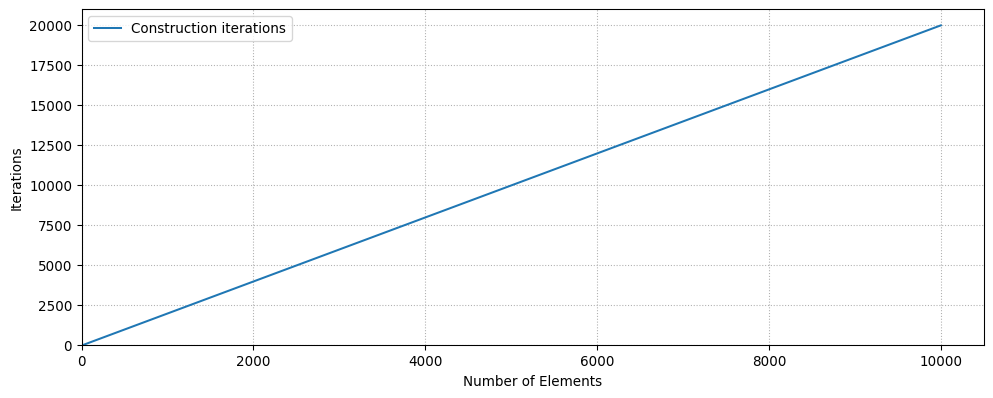

In [19]:
figure(figsize=(12, 4.5), dpi=97)
y = records["Random"]["Construction"]
x = [i+1 for i in range(len(y))]
plt.plot(x, y, label="Construction iterations")
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.legend()
plt.xlabel("Number of Elements")
plt.ylabel("Iterations")
plt.grid(visible=True, linestyle=':')
plt.savefig("./lab6_v2_data/task7_construction.png", dpi=150, bbox_inches="tight")
plt.show()

## Range Query Time v/s Number of Elements

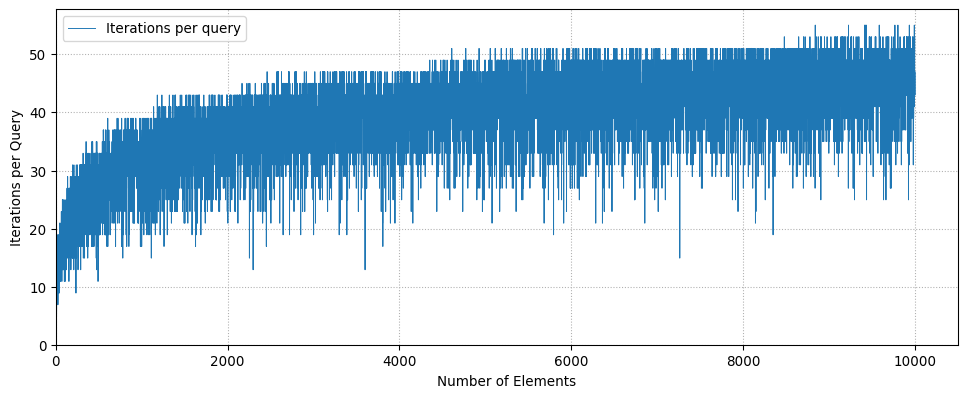

In [20]:
figure(figsize=(12, 4.5), dpi=97)
y = records["Random"]["Query"]
x = [i+1 for i in range(len(y))]
plt.plot(x, y, label="Iterations per query", linewidth=0.7)
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.legend()
plt.xlabel("Number of Elements")
plt.ylabel("Iterations per Query")
plt.grid(visible=True, linestyle=':')
plt.savefig("./lab6_v2_data/task7_query.png", dpi=150, bbox_inches="tight")
plt.show()

## Point Update Time v/s Number of Elements

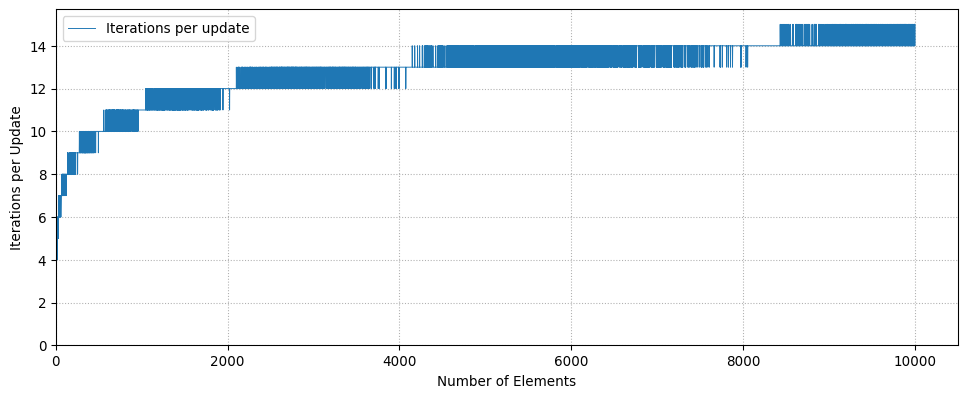

In [21]:
figure(figsize=(12, 4.5), dpi=97)
y = records["Random"]["Update"]
x = [i+1 for i in range(len(y))]
plt.plot(x, y, label="Iterations per update", linewidth=0.7)
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.legend()
plt.xlabel("Number of Elements")
plt.ylabel("Iterations per Update")
plt.grid(visible=True, linestyle=':')
plt.savefig("./lab6_v2_data/task7_update.png", dpi=150, bbox_inches="tight")
plt.show()

## Tree Height v/s Number of Elements

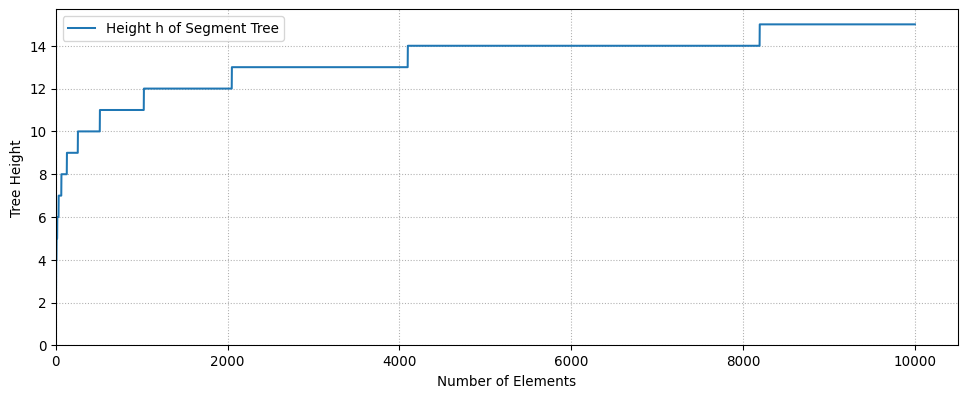

In [22]:
figure(figsize=(12, 4.5), dpi=97)
y = records["Random"]["Height"]
x = [i+1 for i in range(len(y))]
plt.plot(x, y, label="Height h of Segment Tree")
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.legend()
plt.xlabel("Number of Elements")
plt.ylabel("Tree Height")
plt.grid(visible=True, linestyle=':')
plt.savefig("./lab6_v2_data/task7_height.png", dpi=150, bbox_inches="tight")
plt.show()

# Q8.

Implement a linear-search-based approach for finding the minimum and maximum in a given range and experimentally compare its execution time with the Segment Tree approach.

The linear search (`linear_range_search`) is implemented above. The comparison is measured for every size separately: for each size, 100 random ranges `[L, R]` are answered by both approaches on the same array, the two answers are asserted to be equal, and the iterations are averaged.

## Segment Tree v/s Linear Search (Query)

In [23]:
def ST_Query_Compared(values: list[int], query_ranges: list):
    # Average iterations of the Segment Tree and of the linear search on the same ranges
    stree, _ = ST_Build_Measured(values)
    query_counts, linear_counts = [], []
    for left, right in query_ranges:
        result, query_count = ST_Query_Measured(stree, left, right)
        expected, linear_count = Linear_Search_Measured(values, left, right)
        assert result == expected, f"query({left}, {right}) disagrees with linear search"
        query_counts.append(query_count)
        linear_counts.append(linear_count)
    return sum(query_counts) / len(query_counts), sum(linear_counts) / len(linear_counts)


task8_rows = []
for size in SIZES:
    assert size <= len(arr1), "n cannot exceed the length of arr1"
    start_idx = random.randint(0, len(arr1) - size)
    values = arr1[start_idx : start_idx + size]
    size_ranges = []
    for _ in range(100):
        left = random.randrange(size)
        size_ranges.append((left, random.randrange(left, size)))
    query_avg, linear_avg = ST_Query_Compared(values, size_ranges)
    task8_rows.append({"Elements": size, "Segment Tree Average Query Iterations": query_avg,
                       "Linear Search Average Iterations": linear_avg})

task8_df = pd.DataFrame(task8_rows)
task8_df

,Elements,Segment Tree Average Query Iterations,Linear Search Average Iterations
0,100,18.94,25.45
1,500,27.34,133.20
2,1000,31.28,276.88
3,5000,40.90,1301.95
4,10000,43.90,2113.07


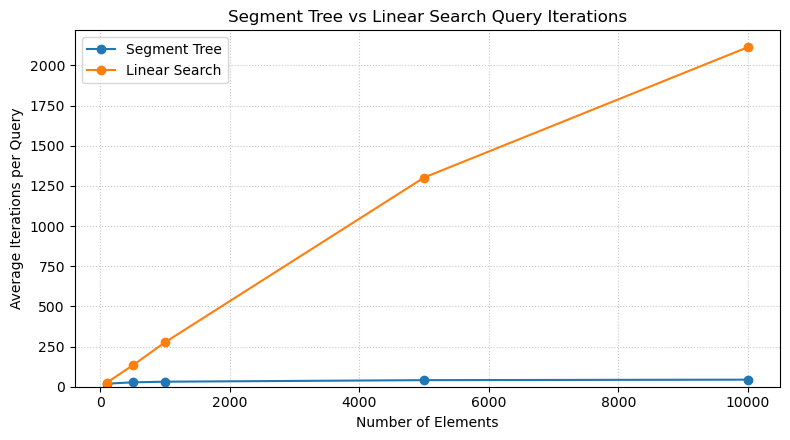

In [24]:
plt.figure(figsize=(8, 4.5))
plt.plot(task8_df["Elements"], task8_df["Segment Tree Average Query Iterations"], marker="o", label="Segment Tree")
plt.plot(task8_df["Elements"], task8_df["Linear Search Average Iterations"], marker="o", label="Linear Search")
plt.xlabel("Number of Elements")
plt.ylabel("Average Iterations per Query")
plt.ylim(bottom=0)
plt.title("Segment Tree vs Linear Search Query Iterations")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.7)
plt.tight_layout()
plt.savefig("./lab6_v2_data/task8_query_vs_linear.png", dpi=150, bbox_inches="tight")
plt.show()

# Q9.

Perform experiments using random, sorted, and reverse-sorted input data and provide a brief analysis of the results.

The same 10000 values and the same query ranges and updates are used for all three input orders. As in Q7, everything is recorded for every size from 1 to 10000 (the random order was already recorded above), and the query comparison with the linear search is again measured for every size separately (on the same 100 ranges for all three orders). The graphs and measurements are analysed below.

In [25]:
sorted_values = sorted(random_values)
input_orders = {
    "Sorted": sorted_values,
    "Reverse Sorted": list(reversed(sorted_values)),
}
for order_name, values in input_orders.items():
    records[order_name] = ST_Recorded(values, query_ranges, point_updates)

task9_rows = []
for order_name in ["Random", "Sorted", "Reverse Sorted"]:
    rec = records[order_name]
    task9_rows.append({
        "Elements": N,
        "Input Order": order_name,
        "Height": rec["Height"][N - 1],
        "Construction Iterations": rec["Construction"][N - 1],
        "Query Iterations": size_mean(rec["Query"], N),
        "Update Iterations": size_mean(rec["Update"], N),
    })

task9_df = pd.DataFrame(task9_rows)
print("Values at 10000 elements; query/update iterations are the mean over the last 10% of the sizes")
task9_df

Values at 10000 elements; query/update iterations are the mean over the last 10% of the sizes


,Elements,Input Order,Height,Construction Iterations,Query Iterations,Update Iterations
0,10000,Random,15,19999,44.88,14.261
1,10000,Sorted,15,19999,44.88,14.261
2,10000,Reverse Sorted,15,19999,44.88,14.261


## Construction Comparison

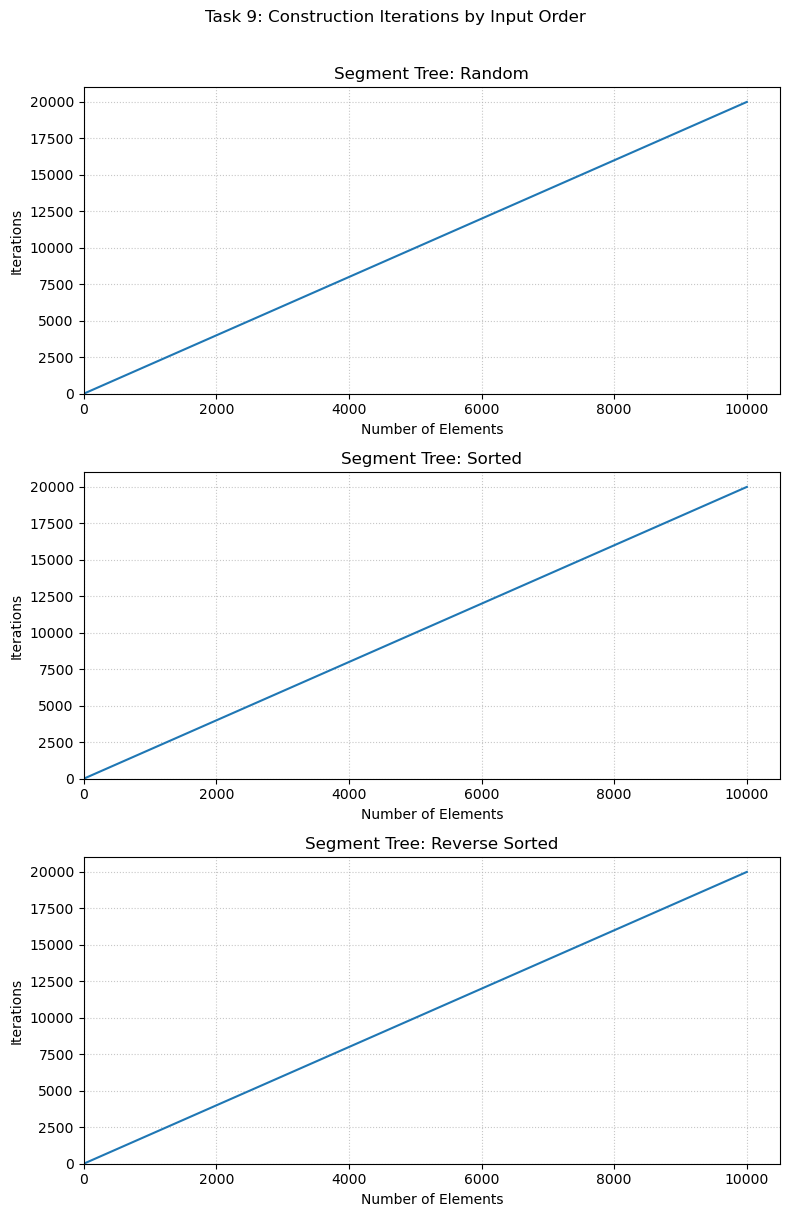

In [26]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ["Random", "Sorted", "Reverse Sorted"]):
    y = records[order_name]["Construction"]
    x = [i+1 for i in range(len(y))]
    ax.plot(x, y)
    ax.set_title(f"Segment Tree: {order_name}")
    ax.set_xlabel("Number of Elements")
    ax.set_ylabel("Iterations")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
fig.suptitle("Task 9: Construction Iterations by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./lab6_v2_data/task9_construction.png", dpi=150, bbox_inches="tight")
plt.show()

## Range Query Comparison

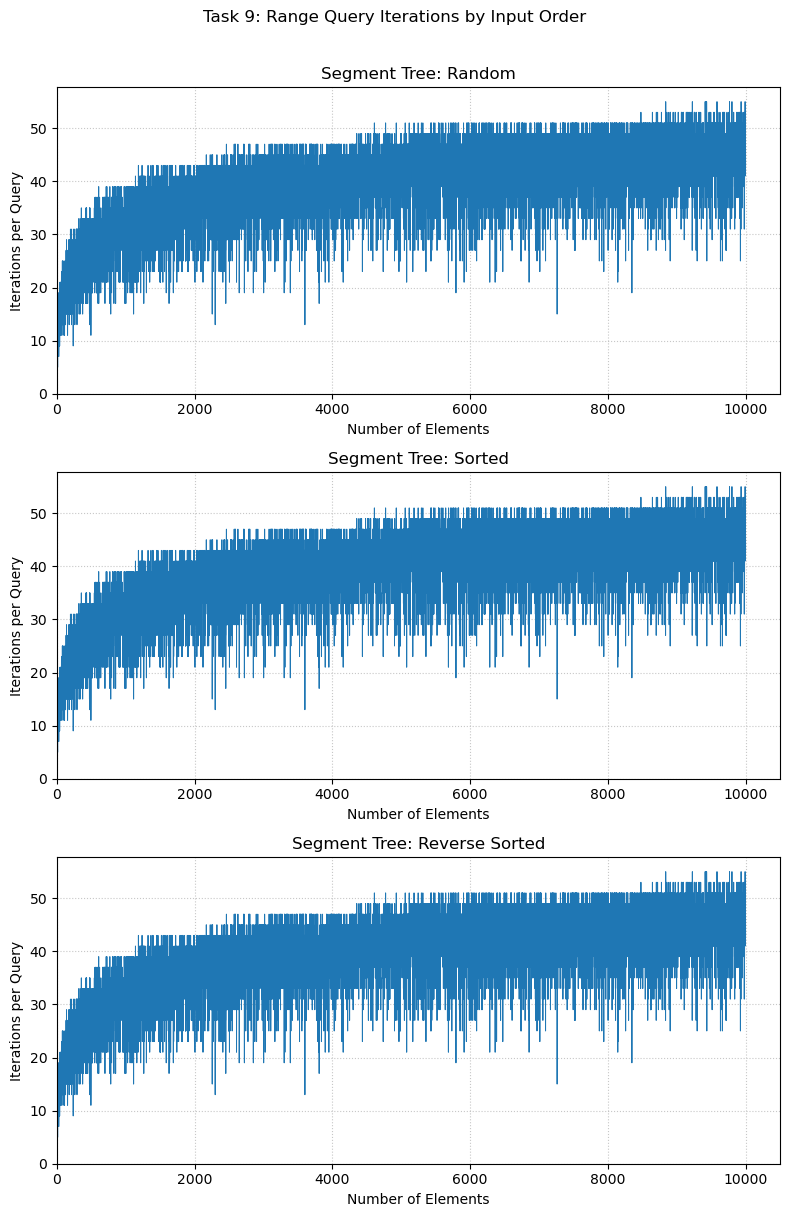

In [27]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ["Random", "Sorted", "Reverse Sorted"]):
    y = records[order_name]["Query"]
    x = [i+1 for i in range(len(y))]
    ax.plot(x, y, linewidth=0.7)
    ax.set_title(f"Segment Tree: {order_name}")
    ax.set_xlabel("Number of Elements")
    ax.set_ylabel("Iterations per Query")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
fig.suptitle("Task 9: Range Query Iterations by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./lab6_v2_data/task9_query.png", dpi=150, bbox_inches="tight")
plt.show()

## Point Update Comparison

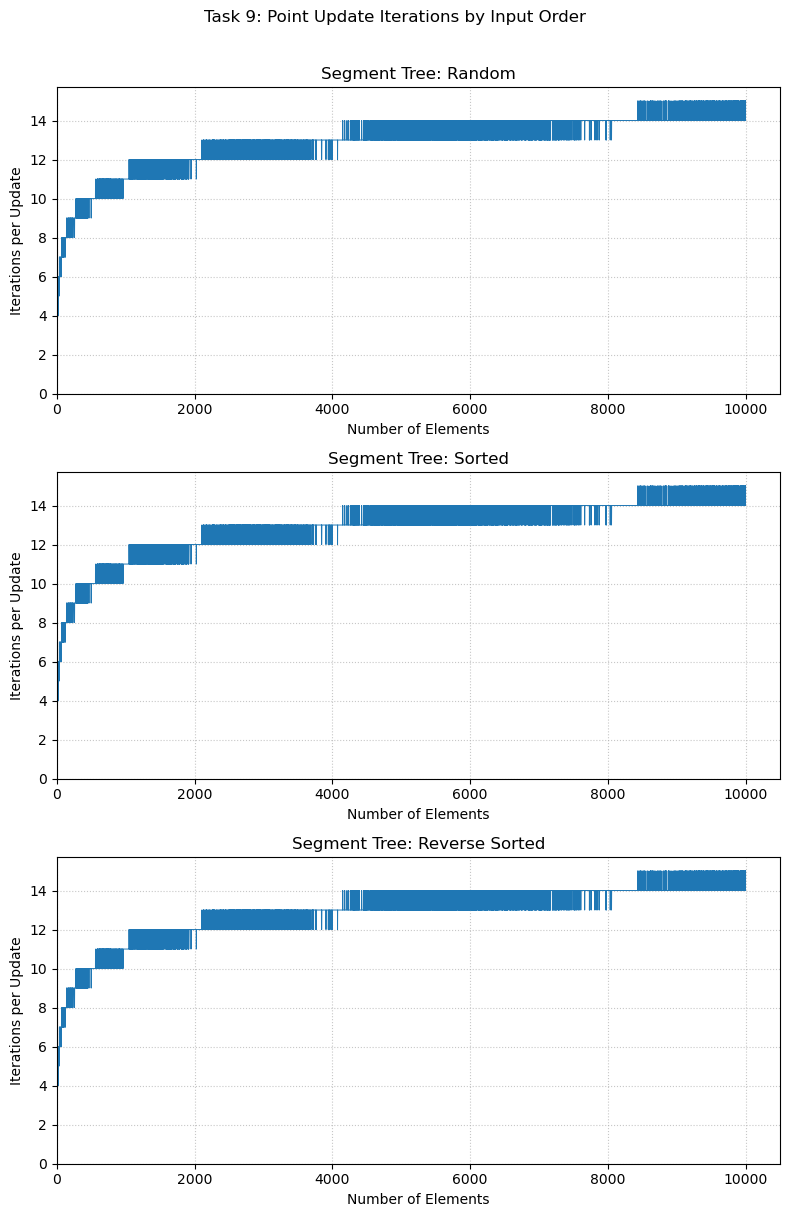

In [28]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ["Random", "Sorted", "Reverse Sorted"]):
    y = records[order_name]["Update"]
    x = [i+1 for i in range(len(y))]
    ax.plot(x, y, linewidth=0.7)
    ax.set_title(f"Segment Tree: {order_name}")
    ax.set_xlabel("Number of Elements")
    ax.set_ylabel("Iterations per Update")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
fig.suptitle("Task 9: Point Update Iterations by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./lab6_v2_data/task9_update.png", dpi=150, bbox_inches="tight")
plt.show()

## Height Comparison

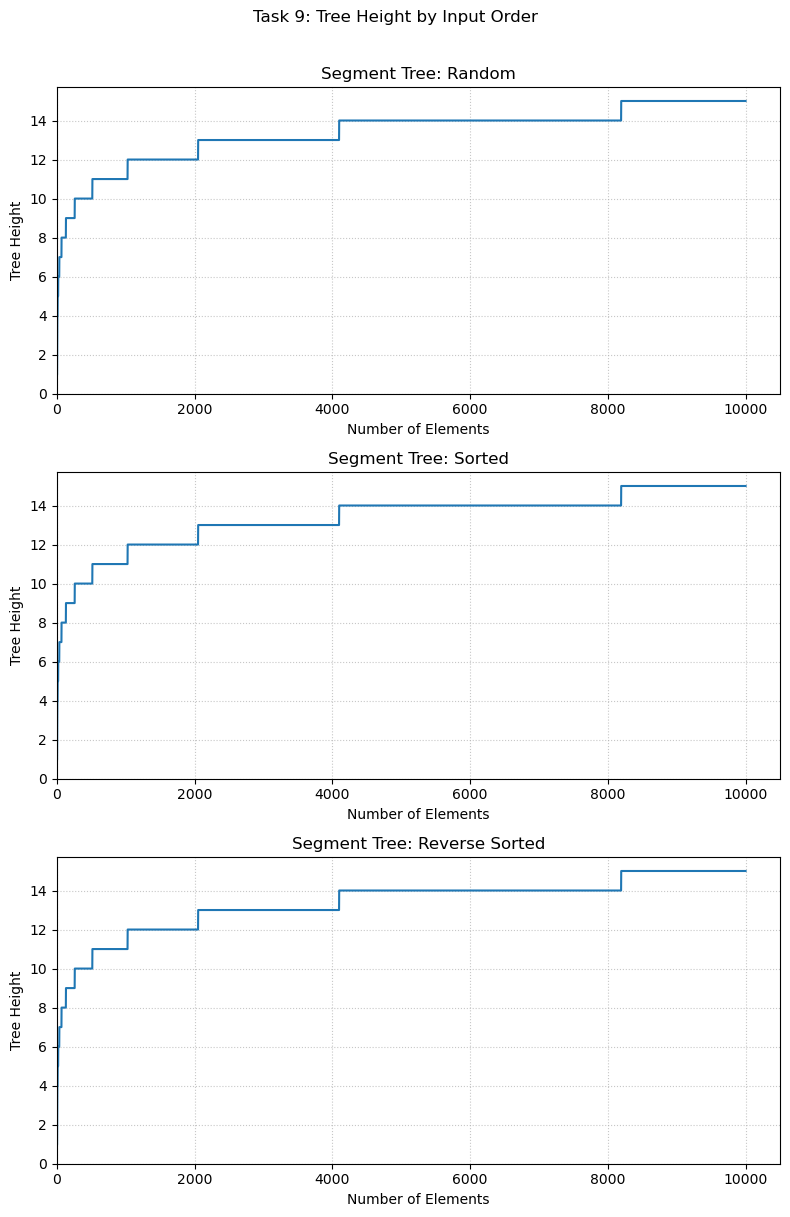

In [29]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ["Random", "Sorted", "Reverse Sorted"]):
    y = records[order_name]["Height"]
    x = [i+1 for i in range(len(y))]
    ax.plot(x, y)
    ax.set_title(f"Segment Tree: {order_name}")
    ax.set_xlabel("Number of Elements")
    ax.set_ylabel("Tree Height")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
fig.suptitle("Task 9: Tree Height by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./lab6_v2_data/task9_height.png", dpi=150, bbox_inches="tight")
plt.show()

## Segment Tree v/s Linear Search Comparison

In [30]:
task9_compare_rows = []
for size in SIZES:
    assert size <= len(arr1), "n cannot exceed the length of arr1"
    start_idx = random.randint(0, len(arr1) - size)
    random_window = arr1[start_idx : start_idx + size]
    sorted_window = sorted(random_window)
    window_orders = {
        "Random": random_window,
        "Sorted": sorted_window,
        "Reverse Sorted": list(reversed(sorted_window)),
    }
    size_ranges = []  # the same 100 ranges for all three input orders
    for _ in range(100):
        left = random.randrange(size)
        size_ranges.append((left, random.randrange(left, size)))
    for order_name, values in window_orders.items():
        query_avg, linear_avg = ST_Query_Compared(values, size_ranges)
        task9_compare_rows.append({"Elements": size, "Input Order": order_name,
                                   "Segment Tree Average Query Iterations": query_avg,
                                   "Linear Search Average Iterations": linear_avg})

task9_compare_df = pd.DataFrame(task9_compare_rows)
task9_compare_df

,Elements,Input Order,Segment Tree Average Query Iterations,Linear Search Average Iterations
0,100,Random,19.22,26.92
1,100,Sorted,19.22,26.92
2,100,Reverse Sorted,19.22,26.92
3,500,Random,27.76,122.57
4,500,Sorted,27.76,122.57
5,500,Reverse Sorted,27.76,122.57
6,1000,Random,31.74,231.29
7,1000,Sorted,31.74,231.29
8,1000,Reverse Sorted,31.74,231.29
9,5000,Random,41.46,1160.04


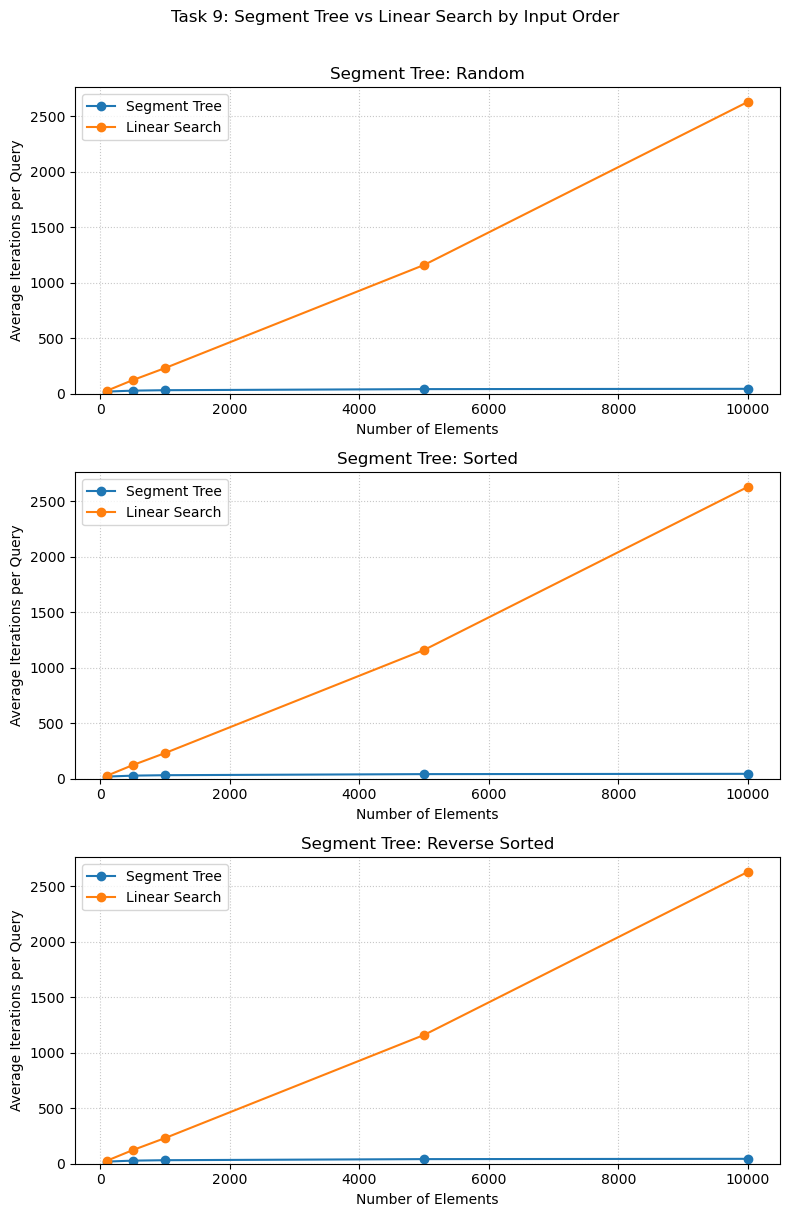

In [31]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ["Random", "Sorted", "Reverse Sorted"]):
    subset = task9_compare_df[task9_compare_df["Input Order"] == order_name]
    ax.plot(subset["Elements"], subset["Segment Tree Average Query Iterations"], marker="o", label="Segment Tree")
    ax.plot(subset["Elements"], subset["Linear Search Average Iterations"], marker="o", label="Linear Search")
    ax.set_title(f"Segment Tree: {order_name}")
    ax.set_xlabel("Number of Elements")
    ax.set_ylabel("Average Iterations per Query")
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
    ax.legend()
fig.suptitle("Task 9: Segment Tree vs Linear Search by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./lab6_v2_data/task9_query_vs_linear.png", dpi=150, bbox_inches="tight")
plt.show()

## Analysis (Q9)

Costs are iteration counts (one node visited, or one element scanned for the linear search). The height, construction, query and update curves were recorded for every size from 1 to 10000. The tables use the value at the given size (height, construction) or the mean over the last 10 % of the sizes (query, update), because a single query or update is noisy. The comparison with the linear search was measured separately for every size, on the same 100 ranges for all input orders.

* **The input order has no effect on the Segment Tree.** For every size from 1 to 10000, random, sorted and reverse-sorted data give *identical* height, construction, query and update costs (at 10000 elements: height 15, 19999 construction iterations, 44.9 query iterations and 14.3 update iterations in all three cases). The shape of the tree and the path of every operation depend only on the size and on the indices involved, never on the stored values. The linear search is order-independent as well, because it always scans all `R - L + 1` elements of the range. This is in contrast to the unbalanced BST of lab 4, whose cost depends heavily on the input order.
* **Height** is a step function of the size, exactly ⌈log₂ *n*⌉ + 1 levels (8, 10, 11, 14 and 15 for 100, 500, 1000, 5000 and 10000 elements), like the AVL curve of lab 3.
* **Construction** visits exactly 2*n* - 1 nodes (199, 999, 1999, 9999 and 19999), a straight line in the size; the notebook asserts this for every size.
* **Range query**: between 100 and 10000 elements the mean cost grows only from 16.6 to 44.9 iterations, and the notebook asserts for every size that a query never visits more than 4 x height nodes. A single query is scattered because it depends on the random range; the plot is a band whose upper edge follows the bound.
* **Point update**: the mean cost grows from 7.7 to 14.3 iterations, and an update never visits more nodes than the height (asserted for every size), since it follows a single root-to-leaf path.
* **Segment Tree vs. linear search**: the linear search grows proportionally to the size (26.9 iterations per query at 100 elements and 2628.9 at 10000, about 98 times more), while the Segment Tree grows from 19.2 to 44.1 (about 2.3 times). For uniformly random ranges the expected range length is about *n*/4, which matches the measured values. At 100 elements the two approaches are close (19.2 vs. 26.9); at 10000 elements the Segment Tree is about 60 times cheaper per query. The price is O(*n*) extra memory and an O(log *n*) update, whereas a plain array updates in O(1).
* **Caveats.** An iteration is not the same amount of work for the two approaches: a node visit of the Segment Tree includes a `merge`, an element scan only one comparison pair. The comparison therefore shows how the costs grow, not their exact ratio in seconds. Only one window of `input0.txt` is used, and `input0.txt` is regenerated every time the first cell runs, so the window changes between runs (the structural numbers above do not). The window is not uniformly random in value, but this cannot affect any result above since no cost depends on the values.

# Q10.

Analyze and report the time and space complexity of:

- Segment Tree construction
- Range Minimum/Maximum Query
- Point Update
- Linear range search

Let *N* be the number of elements and *h* = ⌈log₂ *N*⌉ + 1 the height of the tree.

| Operation | Time | Extra space | Justification (and measured confirmation) |
|:--|:--|:--|:--|
| Construction `build()` | O(*N*) | O(*N*) | T(*N*) = 2T(*N*/2) + O(1), i.e. every one of the 2*N* - 1 nodes is created once. Measured: exactly 2*k* - 1 iterations for every size *k* from 1 to 10000 (asserted). |
| Range Min/Max Query `query(L, R)` | O(log *N*) | O(log *N*) recursion stack | At every level at most two segments are only partially covered and are expanded, so at most 4 nodes per level are visited (at most 4*h*, asserted for every size). Measured: 16.6 to 44.9 iterations on average for 100 to 10000 elements. |
| Point Update `update(i, v)` | O(log *N*) | O(log *N*) recursion stack | A single root-to-leaf path is visited and re-merged on the way back, so at most *h* nodes (asserted for every size). Measured: 7.7 to 14.3 iterations on average. |
| Linear range search | O(*N*) worst case, Θ(R - L + 1) per query | O(1) with a loop; O(R - L + 1) in the recursive version above | Every element of the range is scanned once. Measured: about *n*/4 iterations on average for random ranges (26.9 at 100 and 2628.9 at 10000 elements). |
| Segment Tree (storage) | - | O(*N*) | Two arrays (minimum and maximum) of 4*N* slots are allocated, of which 2*N* - 1 are used. |

For comparison, a point update of the plain array used by the linear search costs O(1), so the Segment Tree trades a logarithmic update and linear extra memory for a logarithmic instead of linear range query.